# Caso 2 · Nodo Internet: predicción de bajas de clientes

**Equipo:** Ignacio Sosa, Nicolas Olivera

Este notebook sigue las consignas del enunciado (pasos 1 a 24). Cada paso tiene su celda; agreguen todas las que necesiten.
Las funciones de `src/` se completan en los archivos `.py`, no en el notebook. Antes de entregar: *Reiniciar y ejecutar todo*.

In [1]:
%load_ext autoreload
%autoreload 2
# autoreload vuelve a cargar los módulos de src/ cada vez que los modifican, sin reiniciar el notebook.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEMILLA = 42

from src.preparacion import agregar_variables, normalizar_metodo_pago
from src.knn import EscaladorEstandar, KNNClasificador
from src.negocio import SUPUESTOS, ganancia_campania, lift, mejor_umbral, probabilidad_de_equilibrio, resultado_por_contacto

In [2]:
import time, warnings
warnings.filterwarnings("ignore")

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.inspection import permutation_importance
from sklearn.metrics import brier_score_loss, average_precision_score

def gs(valor):
    """Formatea guaraníes con punto como separador de miles."""
    return "Gs. " + f"{valor:,.0f}".replace(",", ".")

### Estado de las pruebas automáticas
Ejecuten esta celda cada vez que terminen una función de `src/`.

In [3]:
!python -m pytest -q --tb=no -rf

....................................                                     [100%]
36 passed in 4.00s


## Parte A · Exploración y preparación (`src/preparacion.py`)

**Paso 1.** Carguen `datos/clientes_historico.csv` e informen filas, tipos, nulos por columna, cuentas de empleados, tasa de baja y valores distintos de `metodo_pago`.

In [4]:
hist = pd.read_csv("datos/clientes_historico.csv")
print(f"Filas: {len(hist):,}   Columnas: {hist.shape[1]}   IDs repetidos: {hist.id_cliente.duplicated().sum()}")

resumen = hist.dtypes.astype(str).to_frame("tipo")
resumen["nulos"] = hist.isna().sum()
resumen["% nulos"] = (resumen["nulos"] / len(hist) * 100).round(2)
display(resumen)

n_emp = (hist.segmento == "empleado").sum()
print(f"\nCuentas de empleados: {n_emp:,} ({n_emp / len(hist):.1%})")
print(f"Tasa de baja (todas las cuentas): {hist.baja_90d.mean():.2%}")
print(hist.groupby("segmento").baja_90d.agg(tasa_baja="mean", cuentas="size").round(4))

print(f"\nValores distintos de metodo_pago: {hist.metodo_pago.nunique()}")
display(hist.metodo_pago.value_counts().to_frame("clientes"))

Filas: 20,000   Columnas: 23   IDs repetidos: 0


,tipo,nulos,% nulos
id_cliente,str,0,0.00
fecha_corte,str,0,0.00
segmento,str,0,0.00
fecha_alta,str,0,0.00
edad_titular,int64,0,0.00
zona,str,0,0.00
plan_mbps,int64,0,0.00
tipo_contrato,str,0,0.00
fin_permanencia,str,11491,57.46
tiene_tv,str,0,0.00



Cuentas de empleados: 612 (3.1%)
Tasa de baja (todas las cuentas): 7.67%
             tasa_baja  cuentas
segmento                       
empleado        0.0033      612
residencial     0.0791    19388

Valores distintos de metodo_pago: 18


,clientes
metodo_pago,
debito_automatico,6656
transferencia,4732
tarjeta_credito,4657
efectivo,2800
Debito_Automatico,107
Débito automático,104
Transferencia,101
transferencia bancaria,97
DEBITO AUTOMATICO,95


**Paso 2.** Implementen `normalizar_metodo_pago` y `agregar_variables` hasta que pasen `tests/test_preparacion.py`. Apliquen la función y excluyan las cuentas de empleados.

In [5]:
df = agregar_variables(hist)
print("metodo_pago luego de normalizar:", sorted(df.metodo_pago.unique()))

df = df[df.segmento != "empleado"].reset_index(drop=True)
print(f"Clientes residenciales: {len(df):,}   Tasa de baja: {df.baja_90d.mean():.2%}")
display(df[["antiguedad_meses", "meses_hasta_fin_permanencia", "sin_permanencia_3m"]].describe().T.round(2))

metodo_pago luego de normalizar: ['debito_automatico', 'efectivo', 'tarjeta_credito', 'transferencia']
Clientes residenciales: 19,388   Tasa de baja: 7.91%


,count,mean,std,min,25%,50%,75%,max
antiguedad_meses,19388.0,36.47,31.43,0.0,9.03,28.29,57.01,109.99
meses_hasta_fin_permanencia,19388.0,3.69,5.81,0.0,0.00,0.00,6.41,24.01
sin_permanencia_3m,19388.0,0.66,0.47,0.0,0.00,1.00,1.00,1.00


**Paso 3.** Tasa de baja por tipo de contrato, `sin_permanencia_3m`, zona, antigüedad, reclamos técnicos y consulta de baja web; zona este con cargo mayor a Gs. 280.000 contra el resto. Tres hallazgos para el negocio.

,tasa_baja,clientes
tipo_contrato,,
12_meses,0.0544,5584
24_meses,0.0415,2672
mensual,0.1004,11132


,tasa_baja,clientes
sin_permanencia_3m,,
0,0.0380,6651
1,0.1005,12737


,tasa_baja,clientes
zona,,
centro,0.0565,3537
este,0.1543,3915
norte,0.0563,4242
oeste,0.0741,3456
sur,0.0552,4238


,tasa_baja,clientes
antigüedad (meses),,
<6,0.0900,3189
6-12,0.0855,3148
12-24,0.0561,2462
24-48,0.0793,4868
48+,0.0792,5721


,tasa_baja,clientes
reclamos técnicos 90d,,
0,0.0571,12427
1,0.0921,4703
2,0.1383,1489
3+,0.2393,769


,tasa_baja,clientes
consultó baja web,,
0,0.0596,18240
1,0.3885,1148


,tasa_baja,clientes
zona este con cargo alto,,
este y cargo > 280.000,0.2822,1375
resto,0.0636,18013


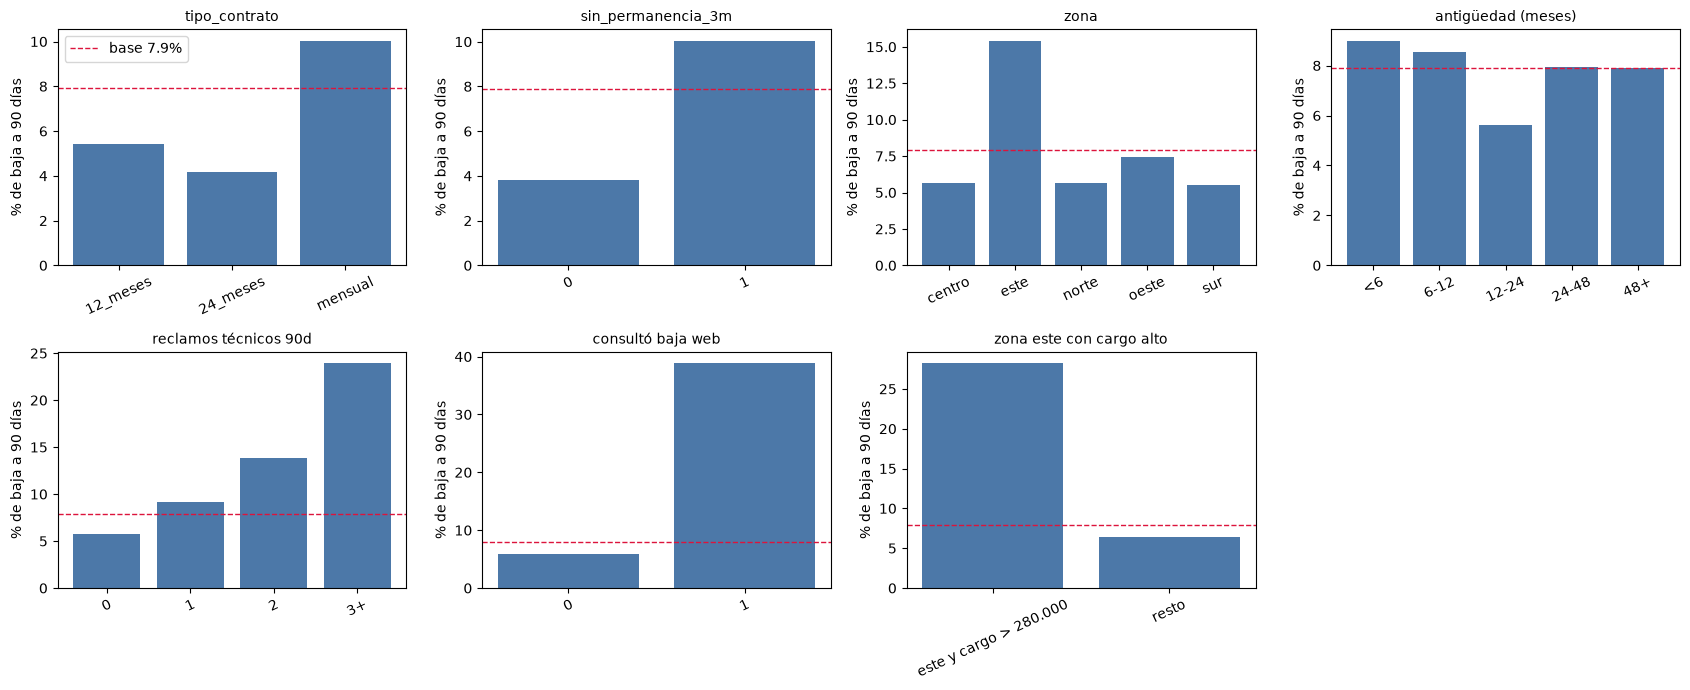

In [6]:
def tasa_por(serie, nombre=None):
    t = df.groupby(serie, observed=True).baja_90d.agg(tasa_baja="mean", clientes="size")
    t.index.name = nombre or t.index.name
    return t

este_caro = ((df.zona == "este") & (df.cargo_mensual_gs > 280_000)).map({True: "este y cargo > 280.000", False: "resto"})
tablas = {
    "tipo_contrato": tasa_por(df.tipo_contrato, "tipo_contrato"),
    "sin_permanencia_3m": tasa_por(df.sin_permanencia_3m, "sin_permanencia_3m"),
    "zona": tasa_por(df.zona, "zona"),
    "antigüedad (meses)": tasa_por(pd.cut(df.antiguedad_meses, [0, 6, 12, 24, 48, np.inf], right=False,
                                         labels=["<6", "6-12", "12-24", "24-48", "48+"]), "antigüedad (meses)"),
    "reclamos técnicos 90d": tasa_por(df.reclamos_tecnicos_90d.clip(upper=3).map({0: "0", 1: "1", 2: "2", 3: "3+"}), "reclamos técnicos 90d"),
    "consultó baja web": tasa_por(df.consulto_baja_web_30d, "consultó baja web"),
    "zona este con cargo alto": tasa_por(este_caro, "zona este con cargo alto"),
}
for nombre, t in tablas.items():
    display(t.round(4))

fig, ejes = plt.subplots(2, 4, figsize=(17, 7))
base = df.baja_90d.mean()
for ax, (nombre, t) in zip(ejes.ravel(), tablas.items()):
    ax.bar(t.index.astype(str), t.tasa_baja * 100, color="#4C78A8")
    ax.axhline(base * 100, color="crimson", ls="--", lw=1, label=f"base {base:.1%}")
    ax.set_title(nombre, fontsize=10); ax.set_ylabel("% de baja a 90 días"); ax.tick_params(axis="x", rotation=25)
ejes.ravel()[0].legend(); ejes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

In [7]:
# Complemento descriptivo: ¿por qué se van los del grupo "este con cargo alto"? (motivo_baja solo para describir, nunca como variable)
solo_bajas = df[df.baja_90d == 1].copy()
solo_bajas["grupo"] = este_caro[solo_bajas.index].values
display(pd.crosstab(solo_bajas.grupo, solo_bajas.motivo_baja, normalize="index").round(3))
print(solo_bajas.grupo.value_counts().to_dict())

motivo_baja,calidad_servicio,competencia,mudanza,otros,precio
grupo,,,,,
este y cargo > 280.000,0.142,0.448,0.095,0.046,0.268
resto,0.295,0.206,0.151,0.077,0.271


{'resto': 1145, 'este y cargo > 280.000': 388}


**Tres hallazgos para el negocio.**
1. **Quien consulta la baja en la web ya está con un pie afuera:** se va el 38,9% contra 6,0% del resto (6,5 veces más). Es solo el 5,9% de la base (1.148 clientes), así que es un grupo chico y muy accionable.
2. **La zona este con cargo alto es un foco de fuga.** La zona este se va el 15,4% (las demás, entre 5,5% y 7,4%), y el grupo "este con cargo > Gs. 280.000" (1.375 clientes) se va el 28,2% contra 6,4% del resto. Entre los que se fueron de ese grupo, el 44,8% cita la competencia (20,6% en el resto), lo que sugiere presión competitiva en esa zona.
3. **Sin permanencia y con reclamos técnicos, el riesgo sube.** Sin permanencia a 3 meses la baja es 10,1% contra 3,8%; y con reclamos técnicos pasa de 5,7% (0 reclamos) a 9,2%, 13,8% y 23,9% (3 o más). La antigüedad, en cambio, no muestra un patrón claro (entre 5,6% y 9,0% según el tramo).

**Paso 4.** Columnas que no pueden usarse como variables y por qué. Demuestren con una tabla el problema de la columna que haría parecer excelente a cualquier modelo.

In [8]:
# Prueba: ¿qué pasa si el modelo "ve" motivo_baja? (solo se informa cuando el cliente ya se fue)
tabla_fuga = pd.crosstab(
    hist.motivo_baja.notna().map({True: "motivo_baja informado", False: "motivo_baja vacío"}),
    hist.baja_90d.map({0: "se quedó (0)", 1: "se fue (1)"}),
)
display(tabla_fuga)
ap_fuga = average_precision_score(hist.baja_90d, hist.motivo_baja.notna().astype(int))
print(f"AP usando solo 'motivo_baja informado' como puntaje: {ap_fuga:.3f}   (modelo al azar: {hist.baja_90d.mean():.3f})")

excluidas = pd.DataFrame([
    ("baja_90d", "Es la variable a predecir."),
    ("motivo_baja", "Solo existe cuando el cliente ya se fue: contiene la respuesta (fuga de información)."),
    ("id_cliente", "Identificador sin significado: un modelo lo memorizaría."),
    ("fecha_corte", f"Constante en el histórico ({df.fecha_corte.nunique()} valor distinto): no discrimina."),
    ("segmento", f"Constante luego de excluir empleados ({df.segmento.nunique()} valor distinto)."),
    ("fecha_alta", "Fecha cruda: se reemplaza por antiguedad_meses, calculada a la fecha de corte."),
    ("fin_permanencia", "Fecha cruda: se reemplaza por meses_hasta_fin_permanencia y sin_permanencia_3m."),
], columns=["columna", "por qué no es variable del modelo"])
display(excluidas)

baja_90d,se fue (1),se quedó (0)
motivo_baja,,
motivo_baja informado,1535,0
motivo_baja vacío,0,18465


AP usando solo 'motivo_baja informado' como puntaje: 1.000   (modelo al azar: 0.077)


,columna,por qué no es variable del modelo
0,baja_90d,Es la variable a predecir.
1,motivo_baja,Solo existe cuando el cliente ya se fue: conti...
2,id_cliente,Identificador sin significado: un modelo lo me...
3,fecha_corte,Constante en el histórico (1 valor distinto): ...
4,segmento,Constante luego de excluir empleados (1 valor ...
5,fecha_alta,Fecha cruda: se reemplaza por antiguedad_meses...
6,fin_permanencia,Fecha cruda: se reemplaza por meses_hasta_fin_...


**Paso 5.** División 75/25 estratificada por `baja_90d` con `random_state=42`.

In [9]:
NUM = ["edad_titular", "plan_mbps", "dia_vencimiento", "cargo_mensual_gs", "uso_mensual_gb", "dispositivos_promedio",
       "velocidad_medida_pct", "horas_sin_servicio_90d", "reclamos_tecnicos_90d", "visitas_tecnicas_12m",
       "facturas_atrasadas_6m", "consulto_baja_web_30d", "antiguedad_meses", "meses_hasta_fin_permanencia", "sin_permanencia_3m"]
CAT = ["zona", "tipo_contrato", "tiene_tv", "metodo_pago"]
LOG = ["uso_mensual_gb", "horas_sin_servicio_90d"]

X = df[NUM + CAT]
y = df["baja_90d"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEMILLA)
print(f"Entrenamiento: {len(Xtr):,} clientes (tasa de baja {ytr.mean():.2%})")
print(f"Prueba:        {len(Xte):,} clientes (tasa de baja {yte.mean():.2%})")

Entrenamiento: 14,541 clientes (tasa de baja 7.91%)
Prueba:        4,847 clientes (tasa de baja 7.90%)


## Parte B · Preprocesamiento y KNN desde cero (`src/knn.py`)

**Paso 6.** `ColumnTransformer`: imputación por mediana, `np.log1p` en `uso_mensual_gb` y `horas_sin_servicio_90d`, estandarización y `OneHotEncoder(handle_unknown="ignore")`.

In [10]:
def armar_preprocesador(num=NUM, cat=CAT, log=LOG, estandarizar=True):
    """Imputa por mediana, aplica log1p a las variables de `log`, estandariza (opcional) y codifica las categóricas."""
    sin_log = [c for c in num if c not in log]
    con_log = [c for c in num if c in log]
    esc = [("esc", StandardScaler())] if estandarizar else []
    partes = []
    if sin_log:
        partes.append(("num", Pipeline([("imp", SimpleImputer(strategy="median"))] + esc), sin_log))
    if con_log:
        partes.append(("log", Pipeline([("imp", SimpleImputer(strategy="median")),
                                        ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one"))] + esc), con_log))
    if cat:
        partes.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat))
    return ColumnTransformer(partes)

prep6 = armar_preprocesador()
Ztr = prep6.fit_transform(Xtr)   # se ajusta SOLO con entrenamiento
Zte = prep6.transform(Xte)
print("Matriz de entrenamiento:", Ztr.shape, "| prueba:", Zte.shape)
print(list(prep6.get_feature_names_out()))

Matriz de entrenamiento: (14541, 29) | prueba: (4847, 29)
['num__edad_titular', 'num__plan_mbps', 'num__dia_vencimiento', 'num__cargo_mensual_gs', 'num__dispositivos_promedio', 'num__velocidad_medida_pct', 'num__reclamos_tecnicos_90d', 'num__visitas_tecnicas_12m', 'num__facturas_atrasadas_6m', 'num__consulto_baja_web_30d', 'num__antiguedad_meses', 'num__meses_hasta_fin_permanencia', 'num__sin_permanencia_3m', 'log__uso_mensual_gb', 'log__horas_sin_servicio_90d', 'cat__zona_centro', 'cat__zona_este', 'cat__zona_norte', 'cat__zona_oeste', 'cat__zona_sur', 'cat__tipo_contrato_12_meses', 'cat__tipo_contrato_24_meses', 'cat__tipo_contrato_mensual', 'cat__tiene_tv_no', 'cat__tiene_tv_si', 'cat__metodo_pago_debito_automatico', 'cat__metodo_pago_efectivo', 'cat__metodo_pago_tarjeta_credito', 'cat__metodo_pago_transferencia']


**Paso 7.** Implementen `EscaladorEstandar` y `KNNClasificador` hasta que pasen `tests/test_knn.py`.

In [11]:
!python -m pytest -q tests/test_knn.py

...............                                                          [100%]
15 passed in 3.94s


**Paso 8.** Su `KNNClasificador` contra `KNeighborsClassifier` con k=51 y pesos por distancia: probabilidades iguales y tiempo de cada uno.

In [13]:
t0 = time.perf_counter()
propio = KNNClasificador(k=51, pesos="distancia").fit(Ztr, ytr)
p_propio = propio.predict_proba(Zte)
t_propio = time.perf_counter() - t0

t0 = time.perf_counter()
ref = KNeighborsClassifier(n_neighbors=51, weights="distance").fit(Ztr, ytr)
p_ref = ref.predict_proba(Zte)
t_ref = time.perf_counter() - t0

print(f"Máxima diferencia absoluta entre probabilidades: {np.abs(p_propio - p_ref).max():.2e}")
print("¿Mismas predicciones de clase?", np.array_equal(propio.predict(Zte), ref.predict(Zte)))
display(pd.DataFrame({"implementación": ["KNNClasificador (propio)", "KNeighborsClassifier (sklearn)"],
                      "tiempo fit + predict_proba (s)": [t_propio, t_ref]}).round(2))

Máxima diferencia absoluta entre probabilidades: 2.22e-16
¿Mismas predicciones de clase? True


,implementación,tiempo fit + predict_proba (s)
0,KNNClasificador (propio),2.32
1,KNeighborsClassifier (sklearn),0.29


## Parte C · Ajuste de KNN

**Paso 9.** AP de KNN con k=25, con y sin estandarizar (validación cruzada estratificada de 5 particiones). Expliquen la diferencia.

In [14]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

print("Desvío estándar de algunas variables (antes de estandarizar):")
display(Xtr[["cargo_mensual_gs", "uso_mensual_gb", "plan_mbps", "edad_titular", "reclamos_tecnicos_90d", "consulto_baja_web_30d"]].std().round(2).to_frame("desvío"))

res9 = {}
for nombre, estandarizar in [("estandarizado", True), ("sin estandarizar", False)]:
    modelo = Pipeline([("prep", armar_preprocesador(estandarizar=estandarizar)), ("knn", KNNClasificador(k=25))])
    res9[nombre] = cross_val_score(modelo, Xtr, ytr, cv=cv, scoring="average_precision")
tabla9 = pd.DataFrame({n: {"AP medio": s.mean(), "desvío entre particiones": s.std()} for n, s in res9.items()}).T
tabla9.loc["referencia: azar (tasa de baja)", "AP medio"] = ytr.mean()
display(tabla9.round(4))

Desvío estándar de algunas variables (antes de estandarizar):


,desvío
cargo_mensual_gs,79434.27
uso_mensual_gb,373.45
plan_mbps,270.90
edad_titular,12.62
reclamos_tecnicos_90d,0.92
consulto_baja_web_30d,0.24


,AP medio,desvío entre particiones
estandarizado,0.3244,0.0126
sin estandarizar,0.1456,0.0149
referencia: azar (tasa de baja),0.0791,NaN


Estandarizar duplica el AP: 0,324 contra 0,146 (el azar da 0,079). KNN decide por distancias, y sin estandarizar las variables de mayor escala mandan. El cargo mensual tiene un desvío de unos 79.000, el uso de unos 373 GB y el plan de unos 271 Mbps, mientras que una variable de 0 o 1 como `consulto_baja_web_30d` tiene 0,24. Los vecinos terminan siendo los clientes de cargo, uso y plan parecidos, y las señales más fuertes de baja (consulta web, reclamos, permanencia) casi no influyen en la distancia. Se aplicaron la misma imputación, el mismo `log1p` y el mismo one-hot en ambos casos; lo único que cambia es la estandarización.

**Paso 10.** `GridSearchCV` con `average_precision`: k, pesos y `p`. Gráfico de AP en función de k y explicación del k elegido.

Búsqueda terminada en 552 s
Mejor combinación: {'k': 151, 'metrica': 'manhattan', 'pesos': 'distancia'} | AP en validación cruzada = 0.3994


,k,pesos,metrica,AP,desvio
23,151,distancia,manhattan,0.3994,0.0173
27,201,distancia,manhattan,0.3990,0.0172
19,101,distancia,manhattan,0.3938,0.0210
26,201,uniforme,manhattan,0.3902,0.0166
22,151,uniforme,manhattan,0.3896,0.0186
15,75,distancia,manhattan,0.3875,0.0178


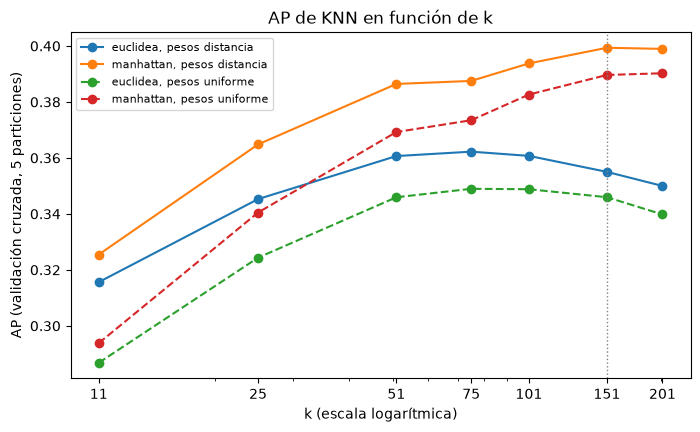

In [15]:
GRID_K = [11, 25, 51, 75, 101, 151, 201]
grilla = {"knn__k": GRID_K, "knn__pesos": ["uniforme", "distancia"], "knn__metrica": ["euclidea", "manhattan"]}  # metrica: p=2 (euclídea) o p=1 (manhattan)
pipe_knn = Pipeline([("prep", armar_preprocesador()), ("knn", KNNClasificador())])

t0 = time.perf_counter()
gs_knn = GridSearchCV(pipe_knn, grilla, scoring="average_precision", cv=cv, n_jobs=-1).fit(Xtr, ytr)
print(f"Búsqueda terminada en {time.perf_counter() - t0:.0f} s")

MEJORES = {k.replace("knn__", ""): v for k, v in gs_knn.best_params_.items()}
print("Mejor combinación:", MEJORES, f"| AP en validación cruzada = {gs_knn.best_score_:.4f}")

res10 = pd.DataFrame(gs_knn.cv_results_)[["param_knn__k", "param_knn__pesos", "param_knn__metrica", "mean_test_score", "std_test_score"]]
res10.columns = ["k", "pesos", "metrica", "AP", "desvio"]
display(res10.sort_values("AP", ascending=False).head(6).round(4))

fig, ax = plt.subplots(figsize=(8, 4.5))
for (pesos, metrica), g in res10.groupby(["pesos", "metrica"]):
    g = g.sort_values("k")
    ax.plot(g.k, g.AP, marker="o", ls="-" if pesos == "distancia" else "--", label=f"{metrica}, pesos {pesos}")
ax.axvline(MEJORES["k"], color="gray", lw=1, ls=":")
ax.set_xscale("log"); ax.set_xticks(GRID_K); ax.set_xticklabels(GRID_K)
ax.set_xlabel("k (escala logarítmica)"); ax.set_ylabel("AP (validación cruzada, 5 particiones)")
ax.set_title("AP de KNN en función de k"); ax.legend(fontsize=8); plt.show()

**Paso 11.** AP sin las variables de permanencia y, por separado, sin `edad_titular`, `dispositivos_promedio` ni `dia_vencimiento`. Conclusión.

In [16]:
PERMANENCIA = ["tipo_contrato", "meses_hasta_fin_permanencia", "sin_permanencia_3m"]
SOSPECHOSAS = ["edad_titular", "dispositivos_promedio", "dia_vencimiento"]

def ap_sin(columnas_fuera):
    num = [c for c in NUM if c not in columnas_fuera]
    cat = [c for c in CAT if c not in columnas_fuera]
    modelo = Pipeline([("prep", armar_preprocesador(num, cat)), ("knn", KNNClasificador(**MEJORES))])
    return cross_val_score(modelo, Xtr[num + cat], ytr, cv=cv, scoring="average_precision")

i_mejor = gs_knn.best_index_
filas = {"Con todas las variables": (gs_knn.best_score_, gs_knn.cv_results_["std_test_score"][i_mejor])}
for nombre, fuera in [("Sin variables de permanencia", PERMANENCIA), ("Sin edad, dispositivos y día de vencimiento", SOSPECHOSAS)]:
    s = ap_sin(fuera)
    filas[nombre] = (s.mean(), s.std())
tabla11 = pd.DataFrame(filas, index=["AP medio", "desvío"]).T
tabla11["cambio vs. todas"] = tabla11["AP medio"] - tabla11.loc["Con todas las variables", "AP medio"]
display(tabla11.round(4))

,AP medio,desvío,cambio vs. todas
Con todas las variables,0.3994,0.0173,0.0000
Sin variables de permanencia,0.3377,0.0107,-0.0616
"Sin edad, dispositivos y día de vencimiento",0.3964,0.0231,-0.0030


## Parte D · Naive Bayes gaussiano como comparación

**Paso 12.** AP de `GaussianNB` con el mismo preprocesamiento, con y sin transformación logarítmica.

In [17]:
res12 = {}
for nombre, log in [("con log1p", LOG), ("sin log1p", [])]:
    nb = Pipeline([("prep", armar_preprocesador(log=log)), ("nb", GaussianNB())])
    s = cross_val_score(nb, Xtr, ytr, cv=cv, scoring="average_precision")
    res12[f"GaussianNB {nombre}"] = (s.mean(), s.std())
res12["KNN elegido (referencia)"] = (gs_knn.best_score_, gs_knn.cv_results_["std_test_score"][gs_knn.best_index_])
display(pd.DataFrame(res12, index=["AP medio", "desvío"]).T.round(4))

,AP medio,desvío
GaussianNB con log1p,0.3515,0.0218
GaussianNB sin log1p,0.3210,0.0236
KNN elegido (referencia),0.3994,0.0173


**Paso 13.** Correlación de Spearman entre las variables de calidad del servicio y relación con el supuesto de independencia.

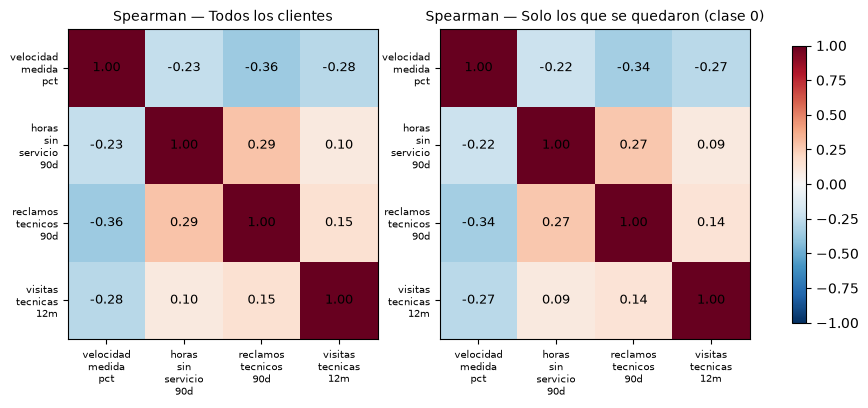

In [18]:
CALIDAD = ["velocidad_medida_pct", "horas_sin_servicio_90d", "reclamos_tecnicos_90d", "visitas_tecnicas_12m"]
rho_todos = Xtr[CALIDAD].corr(method="spearman")
rho_clase0 = Xtr.loc[ytr == 0, CALIDAD].corr(method="spearman")   # dentro de los que se quedaron (condicionada a la clase)

fig, ejes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, rho, titulo in zip(ejes, [rho_todos, rho_clase0], ["Todos los clientes", "Solo los que se quedaron (clase 0)"]):
    im = ax.imshow(rho.values, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(CALIDAD))); ax.set_xticklabels([c.replace("_", "\n") for c in CALIDAD], fontsize=7)
    ax.set_yticks(range(len(CALIDAD))); ax.set_yticklabels([c.replace("_", "\n") for c in CALIDAD], fontsize=7)
    for i in range(len(CALIDAD)):
        for j in range(len(CALIDAD)):
            ax.text(j, i, f"{rho.values[i, j]:.2f}", ha="center", va="center", fontsize=9)
    ax.set_title(f"Spearman — {titulo}", fontsize=10)
fig.colorbar(im, ax=ejes, shrink=0.8); plt.show()

**Paso 14.** Probabilidades fuera de muestra de los dos modelos: puntaje de Brier e histogramas. ¿Cuál exagera más su confianza?

,Brier,prob. media predicha,"% con prob > 0,90","% con prob < 0,01"
KNN,0.0631,0.0567,0.000,5.3985
Naive Bayes,0.1077,0.1455,8.115,50.6361
referencia: tasa base constante,0.0728,NaN,NaN,NaN


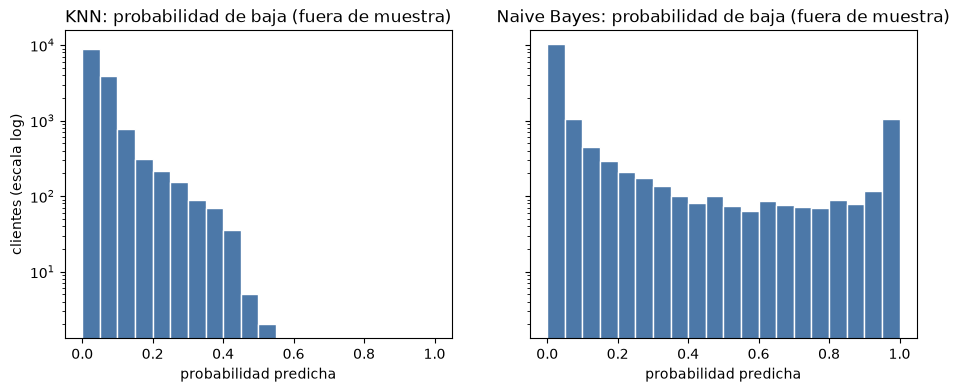

predicha  observada  clientes
modelo      tramo                                     
KNN         [0.0, 0.05)     0.028      0.031      8953
            [0.05, 0.1)     0.068      0.074      3928
            [0.1, 0.2)      0.135      0.239      1092
            [0.2, 0.3)      0.244      0.495       366
            [0.3, 0.5)      0.363      0.700       200
            [0.5, 0.7)      0.503      1.000         2
Naive Bayes [0.0, 0.05)     0.008      0.036     10173
            [0.05, 0.1)     0.070      0.061      1041
            [0.1, 0.2)      0.142      0.086       742
            [0.2, 0.3)      0.247      0.094       381
            [0.3, 0.5)      0.392      0.148       418
            [0.5, 0.7)      0.603      0.153       300
            [0.7, 0.9)      0.804      0.176       306
            [0.9, 1.0)      0.988      0.388      1180

In [19]:
modelo_knn = Pipeline([("prep", armar_preprocesador()), ("knn", KNNClasificador(**MEJORES))])
modelo_nb = Pipeline([("prep", armar_preprocesador()), ("nb", GaussianNB())])

# Probabilidades fuera de muestra: cada cliente se puntúa con un modelo que no lo vio al entrenar
prob_oof = {
    "KNN": cross_val_predict(modelo_knn, Xtr, ytr, cv=cv, method="predict_proba")[:, 1],
    "Naive Bayes": cross_val_predict(modelo_nb, Xtr, ytr, cv=cv, method="predict_proba")[:, 1],
}
tasa_tr = ytr.mean()
brier = {n: brier_score_loss(ytr, p) for n, p in prob_oof.items()}
brier["referencia: tasa base constante"] = brier_score_loss(ytr, np.full(len(ytr), tasa_tr))

resumen14 = pd.DataFrame({
    "Brier": pd.Series(brier),
    "prob. media predicha": pd.Series({n: p.mean() for n, p in prob_oof.items()}),
    "% con prob > 0,90": pd.Series({n: (p > 0.9).mean() * 100 for n, p in prob_oof.items()}),
    "% con prob < 0,01": pd.Series({n: (p < 0.01).mean() * 100 for n, p in prob_oof.items()}),
})
display(resumen14.round(4))

fig, ejes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (n, p) in zip(ejes, prob_oof.items()):
    ax.hist(p, bins=np.linspace(0, 1, 21), color="#4C78A8", edgecolor="white")
    ax.set_yscale("log"); ax.set_title(f"{n}: probabilidad de baja (fuera de muestra)"); ax.set_xlabel("probabilidad predicha")
ejes[0].set_ylabel("clientes (escala log)"); plt.show()

# Calibración: ¿cuando el modelo dice X%, se va realmente X%?
cortes = [0, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9, 1.0001]
filas = []
for n, p in prob_oof.items():
    g = pd.cut(p, cortes, right=False)
    t = pd.DataFrame({"p": p, "y": ytr.values}).groupby(g, observed=True).agg(predicha=("p", "mean"), observada=("y", "mean"), clientes=("y", "size"))
    t.insert(0, "modelo", n); filas.append(t.reset_index(names="tramo"))
display(pd.concat(filas).round(3).set_index(["modelo", "tramo"]))

**Naive Bayes exagera mucho más su confianza.**
- Su puntaje de Brier (0,108) es "peor" que el de predecir siempre la tasa base (0,073), mientras que el de KNN es 0,063.
- Naive Bayes asigna probabilidad menor a 1% al 51% de los clientes y mayor a 90% al 8%; KNN no pasa de 0,7 en ningún caso. Pero cuando Naive Bayes dice "más de 90%", se va solo el 38,8% de esos clientes; y cuando dice "entre 70% y 90%", el 17,6%.
- KNN (con k=151) tiene el problema contrario, es más inofensivo. Cuando predice entre 0,2 y 0,3, se va el 49,5%, y entre 0,3 y 0,5, el 70%. Ordena bien a los clientes pero subestima la probabilidad en el tramo alto.

## Parte E · Economía de la campaña (`src/negocio.py`)

**Paso 15.** Implementen las funciones de `src/negocio.py` hasta que pasen `tests/test_negocio.py`. Informen G⁺, G⁻ y la probabilidad de equilibrio.

In [20]:
g_mas, g_menos = resultado_por_contacto()
p_eq = probabilidad_de_equilibrio()
print(f"G+ (contactar a quien se iba a ir):      {gs(g_mas)}")
print(f"G- (contactar a quien se iba a quedar):  {gs(g_menos)}")
print(f"Probabilidad de equilibrio:              {p_eq:.4f}  ({p_eq:.1%})")

G+ (contactar a quien se iba a ir):      Gs. 310.000
G- (contactar a quien se iba a quedar):  Gs. -130.000
Probabilidad de equilibrio:              0.2955  (29.5%)


In [21]:
!python -m pytest -q tests/test_negocio.py

.......                                                                  [100%]
7 passed in 0.50s


**Paso 16.** Regla comercial sobre el conjunto de entrenamiento: clientes marcados, proporción que se fue y ganancia por cada 1.000 clientes.

In [22]:
marca_tr = ((Xtr.zona == "este") & (Xtr.cargo_mensual_gs > 280_000)).values
n_marcados = marca_tr.sum()
precision_regla = ytr.values[marca_tr].mean()
ganancia_regla_tr = ganancia_campania(ytr.values, marca_tr)
print(f"Clientes marcados por la regla: {n_marcados:,} ({n_marcados / len(ytr):.1%} del entrenamiento)")
print(f"Proporción que se fue (precisión): {precision_regla:.1%}   vs. probabilidad de equilibrio {p_eq:.1%}")
print(f"Ganancia total: {gs(ganancia_regla_tr)}")
print(f"Ganancia por cada 1.000 clientes de la base: {gs(ganancia_regla_tr / len(ytr) * 1000)}")

Clientes marcados por la regla: 1,059 (7.3% del entrenamiento)
Proporción que se fue (precisión): 26.9%   vs. probabilidad de equilibrio 29.5%
Ganancia total: Gs. -12.270.000
Ganancia por cada 1.000 clientes de la base: Gs. -843.821


**Paso 17.** Umbral de cada modelo con `mejor_umbral` sobre probabilidades fuera de muestra, con un máximo del 7% de los clientes. Comparación con la probabilidad de equilibrio.

In [23]:
CAPACIDAD = 0.07   # como máximo el 7% de los clientes
tope_tr = int(CAPACIDAD * len(ytr))
res17 = {n: mejor_umbral(ytr.values, p, max_contactos=tope_tr) for n, p in prob_oof.items()}
sin_tope = {n: mejor_umbral(ytr.values, p) for n, p in prob_oof.items()}

filas = []
for n, r in res17.items():
    c = prob_oof[n] >= r["umbral"]
    filas.append({"modelo": n, "umbral": r["umbral"], "contactados": r["contactados"], "% de la base": r["contactados"] / len(ytr) * 100,
                  "precisión": ytr.values[c].mean(), "ganancia (Gs.)": r["ganancia"], "ganancia por 1.000": r["ganancia"] / len(ytr) * 1000,
                  "umbral sin tope": sin_tope[n]["umbral"], "contactados sin tope": sin_tope[n]["contactados"]})
tabla17 = pd.DataFrame(filas).set_index("modelo")
print(f"Tope de contactos en entrenamiento: {tope_tr:,}   |   probabilidad de equilibrio: {p_eq:.4f}")
display(tabla17.round(3))

elegido = max(res17, key=lambda n: res17[n]["ganancia"])
print("Modelo elegido (mayor ganancia fuera de muestra en entrenamiento):", elegido)

Tope de contactos en entrenamiento: 1,017   |   probabilidad de equilibrio: 0.2955


,umbral,contactados,% de la base,precisión,ganancia (Gs.),ganancia por 1.000,umbral sin tope,contactados sin tope
modelo,,,,,,,,
KNN,0.153,850,5.846,0.513,81340000.0,5593838.113,0.153,850
Naive Bayes,0.996,783,5.385,0.469,59690000.0,4104944.639,0.996,783


Modelo elegido (mayor ganancia fuera de muestra en entrenamiento): KNN


**Paso 18.** Evaluación única en prueba: tabla de estrategias y curva de ganancia acumulada.

,contactados,% de la base,precisión,lift,ganancia (Gs.),ganancia por 1.000
No contactar a nadie,0.0,0.000,NaN,NaN,0.0,0.000000e+00
Contactar a todos,4847.0,100.000,0.079,1.000,-461590000.0,-9.523210e+07
Regla comercial (este y cargo > 280.000),316.0,6.519,0.326,4.125,4240000.0,8.747679e+05
KNN con umbral,292.0,6.024,0.510,6.458,27600000.0,5.694244e+06
Naive Bayes con umbral,257.0,5.302,0.475,6.008,20270000.0,4.181968e+06


lift(KNN, top 6.0%) = 6.46
lift(Naive Bayes, top 5.3%) = 6.01


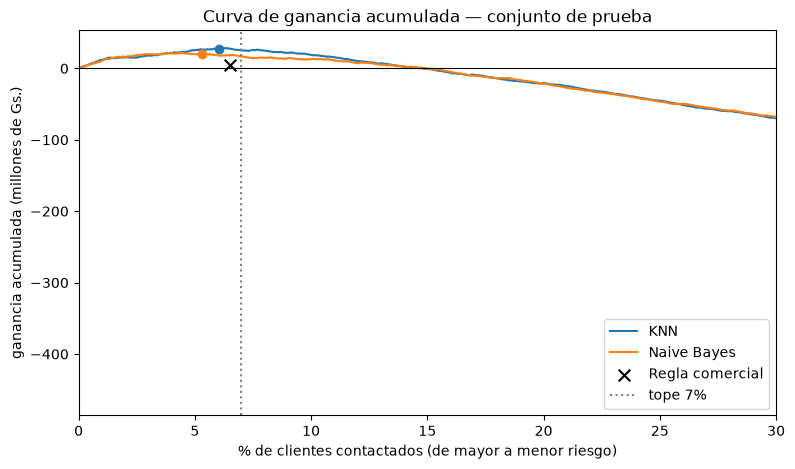

In [24]:
final_knn = Pipeline([("prep", armar_preprocesador()), ("knn", KNNClasificador(**MEJORES))]).fit(Xtr, ytr)
final_nb = Pipeline([("prep", armar_preprocesador()), ("nb", GaussianNB())]).fit(Xtr, ytr)
prob_te = {"KNN": final_knn.predict_proba(Xte)[:, 1], "Naive Bayes": final_nb.predict_proba(Xte)[:, 1]}

yt = yte.values
marca_te = ((Xte.zona == "este") & (Xte.cargo_mensual_gs > 280_000)).values
estrategias = {
    "No contactar a nadie": np.zeros(len(yt), dtype=bool),
    "Contactar a todos": np.ones(len(yt), dtype=bool),
    "Regla comercial (este y cargo > 280.000)": marca_te,
    "KNN con umbral": prob_te["KNN"] >= res17["KNN"]["umbral"],
    "Naive Bayes con umbral": prob_te["Naive Bayes"] >= res17["Naive Bayes"]["umbral"],
}
filas = {}
for nombre, c in estrategias.items():
    n_c = int(c.sum())
    prec = yt[c].mean() if n_c else np.nan
    g = ganancia_campania(yt, c)
    filas[nombre] = {"contactados": n_c, "% de la base": n_c / len(yt) * 100, "precisión": prec,
                     "lift": (prec / yt.mean()) if n_c else np.nan, "ganancia (Gs.)": g, "ganancia por 1.000": g / len(yt) * 1000}
tabla18 = pd.DataFrame(filas).T
display(tabla18.round(3))

# Comprobación del lift con la función de src/negocio.py
for n in ["KNN", "Naive Bayes"]:
    c = estrategias[f"{n} con umbral" if n == "KNN" else "Naive Bayes con umbral"].sum()
    print(f"lift({n}, top {c / len(yt):.1%}) = {lift(yt, prob_te[n], c / len(yt)):.2f}")

# Curva de ganancia acumulada: se contacta de mayor a menor probabilidad
g_mas, g_menos = resultado_por_contacto()
fig, ax = plt.subplots(figsize=(9, 5))
for n, p in prob_te.items():
    orden = np.argsort(-p, kind="stable")
    acum = np.cumsum(np.where(yt[orden] == 1, g_mas, g_menos)) / 1e6
    ax.plot(np.arange(1, len(yt) + 1) / len(yt) * 100, acum, label=n)
    c = estrategias[f"{n} con umbral" if n == "KNN" else "Naive Bayes con umbral"]
    ax.scatter(c.mean() * 100, ganancia_campania(yt, c) / 1e6, zorder=5)
ax.scatter(marca_te.mean() * 100, ganancia_campania(yt, marca_te) / 1e6, color="black", marker="x", s=70, zorder=5, label="Regla comercial")
ax.axvline(CAPACIDAD * 100, color="gray", ls=":", label="tope 7%"); ax.axhline(0, color="black", lw=0.8)
ax.set_xlim(0, 30); ax.set_xlabel("% de clientes contactados (de mayor a menor riesgo)"); ax.set_ylabel("ganancia acumulada (millones de Gs.)")
ax.set_title("Curva de ganancia acumulada — conjunto de prueba"); ax.legend(); plt.show()

## Parte F · Explicación para Fidelización

**Paso 19.** Importancia por permutación del modelo elegido sobre prueba (`average_precision`).

Terminado en 647 s | AP de KNN en prueba sin permutar: 0.4051


,variable,caída de AP,desvío
0,consulto_baja_web_30d,0.1997,0.0109
1,zona,0.0654,0.0081
2,sin_permanencia_3m,0.0235,0.0054
3,reclamos_tecnicos_90d,0.0207,0.0057
4,plan_mbps,0.0191,0.0013
5,cargo_mensual_gs,0.0135,0.0011
6,velocidad_medida_pct,0.0124,0.0025
7,facturas_atrasadas_6m,0.0103,0.0029
8,edad_titular,0.0090,0.0034
9,metodo_pago,0.0076,0.0021


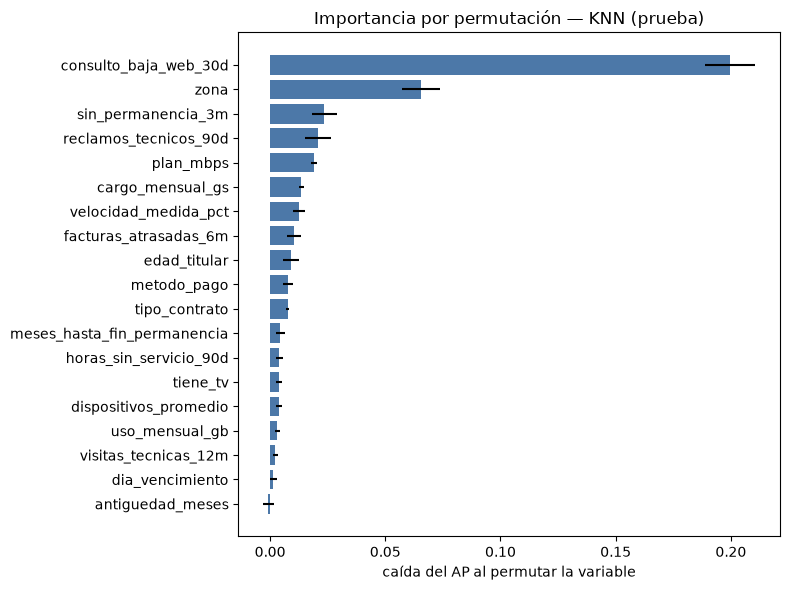

In [25]:
N_REPETICIONES = 3
MAX_MUESTRAS = 1.0
modelo_elegido = final_knn if elegido == "KNN" else final_nb
t0 = time.perf_counter()
imp = permutation_importance(modelo_elegido, Xte, yte, scoring="average_precision", n_repeats=N_REPETICIONES,
                             random_state=SEMILLA, n_jobs=-1, max_samples=MAX_MUESTRAS)
print(f"Terminado en {time.perf_counter() - t0:.0f} s | AP de {elegido} en prueba sin permutar: {average_precision_score(yte, prob_te[elegido]):.4f}")
tabla19 = pd.DataFrame({"variable": Xte.columns, "caída de AP": imp.importances_mean, "desvío": imp.importances_std}).sort_values("caída de AP", ascending=False)
display(tabla19.round(4).reset_index(drop=True))

t = tabla19.sort_values("caída de AP")
plt.figure(figsize=(8, 6)); plt.barh(t.variable, t["caída de AP"], xerr=t["desvío"], color="#4C78A8")
plt.xlabel("caída del AP al permutar la variable"); plt.title(f"Importancia por permutación — {elegido} (prueba)"); plt.tight_layout(); plt.show()

**Paso 20.** Función `explicar_cliente(id_cliente)` y su aplicación a los 3 clientes de mayor riesgo de la campaña, con la oferta propuesta para cada uno.

In [26]:
OFERTAS = {
    "precio": "Descuento sobre el cargo mensual por 3 a 6 meses a cambio de renovar permanencia.",
    "competencia": "Subir de plan o velocidad sin costo por un período y congelar el precio 12 meses para igualar a la competencia.",
    "calidad_servicio": "Visita técnica prioritaria sin costo y crédito por las horas sin servicio; seguimiento a los 30 días.",
    "mudanza": "Traslado gratuito del servicio al nuevo domicilio (el descuento no resuelve este motivo).",
    "otros": "Llamada de un asesor para entender el caso antes de ofrecer un beneficio.",
}
# (variable, signo): signo +1 = valores altos indican más riesgo, -1 = valores bajos indican más riesgo
SENALES = {"reclamos_tecnicos_90d": 1, "horas_sin_servicio_90d": 1, "visitas_tecnicas_12m": 1, "facturas_atrasadas_6m": 1,
           "consulto_baja_web_30d": 1, "sin_permanencia_3m": 1, "cargo_mensual_gs": 1, "velocidad_medida_pct": -1}

def explicar_cliente(id_cliente, clientes=None, modelo=None, historico=None, imprimir=True):
    """Explica por qué el modelo asigna ese riesgo: mira a los k vecinos del cliente en el histórico.
    Por defecto usa `clientes_campania`, `modelo_final` e `historico_res`, que se crean en el Paso 21."""
    clientes = clientes_campania if clientes is None else clientes
    modelo = modelo_final if modelo is None else modelo
    historico = historico_res if historico is None else historico
    fila = clientes[clientes.id_cliente == id_cliente]
    if len(fila) != 1:
        raise ValueError(f"id_cliente {id_cliente!r} no encontrado (o repetido)")
    x = fila[NUM + CAT]
    prob = modelo.predict_proba(x)[0, 1]
    dist, idx = modelo.named_steps["knn"].kneighbors(modelo.named_steps["prep"].transform(x))
    vecinos = historico.iloc[idx[0]]
    se_fueron = vecinos[vecinos.baja_90d == 1]
    motivos = se_fueron.motivo_baja.value_counts(normalize=True)
    motivo_principal = motivos.index[0] if len(motivos) else "otros"

    senales = []
    for var, signo in SENALES.items():
        z = (fila[var].iloc[0] - historico[var].mean()) / historico[var].std()
        if signo * z > 1:
            senales.append((var, fila[var].iloc[0], historico[var].mean(), se_fueron[var].mean()))

    info = {"id_cliente": id_cliente, "prob_baja": prob, "vecinos": len(vecinos), "vecinos_que_se_fueron": len(se_fueron),
            "motivos": motivos.round(3).to_dict(), "motivo_principal": motivo_principal, "oferta": OFERTAS[motivo_principal], "senales": senales}
    if imprimir:
        f = fila.iloc[0]
        print(f"Cliente {id_cliente}: zona {f.zona}, contrato {f.tipo_contrato}, plan {f.plan_mbps} Mbps, cargo {gs(f.cargo_mensual_gs)}")
        print(f"  Probabilidad de baja: {prob:.1%} (umbral de contacto {UMBRAL_CAMPANIA:.1%})")
        print(f"  De sus {len(vecinos)} vecinos más parecidos, {len(se_fueron)} se fueron ({len(se_fueron) / len(vecinos):.0%}).")
        print("  Motivos de baja entre esos vecinos: " + ", ".join(f"{m} {p:.0%}" for m, p in motivos.items()))
        if senales:
            print("  Señales propias de riesgo (valor del cliente | promedio de la base | promedio de vecinos que se fueron):")
            for var, v, base, vec in senales:
                print(f"    - {var}: {v:,.1f} | {base:,.1f} | {vec:,.1f}")
        print(f"  Oferta propuesta ({motivo_principal}): {OFERTAS[motivo_principal]}")
    return info

`explicar_cliente`: Para un cliente busca sus 151 vecinos en el historico, cuenta cuantos se fueron y por qué motivo (aca `motivo_baja` se usa solo para describir casos pasados, no como variable), señala las variables en las que el cliente esta en riesgo respecto de la base (comparadas con las de los vecinos que se fueron) y propone una oferta segun el motivo dominante. Usa los objetos que se crean en el Paso 21 (`modelo_final`, `clientes_campania`, `historico_res`), por eso su aplicacion a los 3 clientes de mayor riesgo esta en la celda posterior al Paso 22, cuando ya existe la lista de la campaña.

## Parte G · Lista de la campaña de octubre

**Paso 21.** Reentrenen el modelo con todos los clientes residenciales del histórico y calculen la probabilidad de baja de `datos/clientes_campania.csv`.

In [27]:
historico_res = df.copy()   # residenciales del histórico, mismo orden con el que se entrena el modelo final
t0 = time.perf_counter()
modelo_final = Pipeline([("prep", armar_preprocesador()), ("knn", KNNClasificador(**MEJORES))]).fit(historico_res[NUM + CAT], historico_res["baja_90d"])

clientes_campania = agregar_variables(pd.read_csv("datos/clientes_campania.csv"))
clientes_campania["prob_baja"] = modelo_final.predict_proba(clientes_campania[NUM + CAT])[:, 1]
print(f"{len(clientes_campania):,} clientes puntuados en {time.perf_counter() - t0:.0f} s "
      f"(fecha de corte: {clientes_campania.fecha_corte.unique()}; empleados: {(clientes_campania.segmento == 'empleado').sum()})")
print(f"Probabilidad media en la campaña: {clientes_campania.loc[clientes_campania.segmento != 'empleado', 'prob_baja'].mean():.3f}"
      f"  |  tasa de baja del histórico: {historico_res.baja_90d.mean():.3f}")

6,000 clientes puntuados en 28 s (fecha de corte: <StringArray>
['2026-09-30']
Length: 1, dtype: str; empleados: 157)
Probabilidad media en la campaña: 0.059  |  tasa de baja del histórico: 0.079


In [28]:
# ¿La base de septiembre se parece a la de mayo? Diferencia estandarizada de cada variable (en desvíos del histórico)
camp_res = clientes_campania[clientes_campania.segmento != "empleado"]
comp = pd.DataFrame({"media histórico (mayo)": historico_res[NUM].mean(), "media campaña (sept.)": camp_res[NUM].mean()})
comp["diferencia en desvíos"] = (comp["media campaña (sept.)"] - comp["media histórico (mayo)"]) / historico_res[NUM].std()
display(comp.reindex(comp["diferencia en desvíos"].abs().sort_values(ascending=False).index).head(8).round(3))
for c in ["zona", "tipo_contrato", "metodo_pago"]:
    display(pd.DataFrame({"histórico": historico_res[c].value_counts(normalize=True), "campaña": camp_res[c].value_counts(normalize=True)}).round(3))

,media histórico (mayo),media campaña (sept.),diferencia en desvíos
plan_mbps,365.814,371.898,0.022
cargo_mensual_gs,244914.225,246674.482,0.022
horas_sin_servicio_90d,3.830,3.690,-0.020
dia_vencimiento,9.488,9.348,-0.018
uso_mensual_gb,349.414,355.113,0.016
edad_titular,44.034,44.217,0.014
facturas_atrasadas_6m,0.425,0.437,0.014
sin_permanencia_3m,0.657,0.653,-0.008


,histórico,campaña
zona,,
centro,0.182,0.176
este,0.202,0.203
norte,0.219,0.213
oeste,0.178,0.189
sur,0.219,0.218


,histórico,campaña
tipo_contrato,,
mensual,0.574,0.571
12_meses,0.288,0.291
24_meses,0.138,0.138


,histórico,campaña
metodo_pago,,
debito_automatico,0.353,0.345
transferencia,0.251,0.252
tarjeta_credito,0.247,0.237
efectivo,0.149,0.166


**Paso 22.** Generen `campania_octubre.csv` (6.000 filas; columnas `id_cliente`, `prob_baja`, `contactar`) y verifiquen: como máximo 420 contactos, ningún empleado, ningún cliente repetido.

In [29]:
UMBRAL_CAMPANIA = res17[elegido]["umbral"]
MAX_CONTACTOS = 420
es_empleado = clientes_campania.segmento == "empleado"
elegibles = clientes_campania[~es_empleado & (clientes_campania.prob_baja >= UMBRAL_CAMPANIA)]
a_contactar = elegibles.sort_values("prob_baja", ascending=False, kind="stable").head(MAX_CONTACTOS).id_cliente

salida = pd.DataFrame({"id_cliente": clientes_campania.id_cliente,
                       "prob_baja": clientes_campania.prob_baja.round(6),
                       "contactar": clientes_campania.id_cliente.isin(a_contactar).astype(int)})
salida.to_csv("campania_octubre.csv", index=False)

# Verificaciones pedidas
chequeo = salida.merge(clientes_campania[["id_cliente", "segmento"]], on="id_cliente")
assert len(salida) == 6000, "deben ser 6.000 filas"
assert salida.contactar.sum() <= 420, "máximo 420 contactos"
assert chequeo.loc[chequeo.contactar == 1, "segmento"].ne("empleado").all(), "no se contacta a empleados"
assert salida.id_cliente.is_unique, "no puede haber clientes repetidos"
print(f"campania_octubre.csv: {len(salida):,} filas | contactos: {salida.contactar.sum()} | empleados contactados: "
      f"{(chequeo.loc[chequeo.contactar == 1, 'segmento'] == 'empleado').sum()} | repetidos: {salida.id_cliente.duplicated().sum()}")
print(f"Umbral aplicado: {UMBRAL_CAMPANIA:.4f} | clientes elegibles por umbral: {len(elegibles):,} | prob. mínima contactada: {salida.loc[salida.contactar == 1, 'prob_baja'].min():.3f}")
display(salida.sort_values("prob_baja", ascending=False).head(5))

campania_octubre.csv: 6,000 filas | contactos: 376 | empleados contactados: 0 | repetidos: 0
Umbral aplicado: 0.1531 | clientes elegibles por umbral: 376 | prob. mínima contactada: 0.154


,id_cliente,prob_baja,contactar
3397,NI-305479,0.575835,1
1773,NI-301055,0.554324,1
1289,NI-305108,0.515128,1
1612,NI-303555,0.511492,0
4869,NI-305922,0.508427,1


In [30]:
# Aplicación del Paso 20: los 3 clientes de mayor riesgo de la campaña
top3 = clientes_campania[~es_empleado].nlargest(3, "prob_baja").id_cliente.tolist()
for id_top in top3:
    explicar_cliente(id_top)
    print()

Cliente NI-305479: zona este, contrato mensual, plan 1000 Mbps, cargo Gs. 428.000
  Probabilidad de baja: 57.6% (umbral de contacto 15.3%)
  De sus 151 vecinos más parecidos, 84 se fueron (56%).
  Motivos de baja entre esos vecinos: precio 36%, competencia 29%, calidad_servicio 18%, mudanza 12%, otros 6%
  Señales propias de riesgo (valor del cliente | promedio de la base | promedio de vecinos que se fueron):
    - horas_sin_servicio_90d: 22.3 | 3.8 | 8.3
    - consulto_baja_web_30d: 1.0 | 0.1 | 0.8
    - cargo_mensual_gs: 428,000.0 | 244,914.2 | 382,178.6
    - velocidad_medida_pct: 52.7 | 88.7 | 72.8
  Oferta propuesta (precio): Descuento sobre el cargo mensual por 3 a 6 meses a cambio de renovar permanencia.

Cliente NI-301055: zona este, contrato mensual, plan 1000 Mbps, cargo Gs. 448.000
  Probabilidad de baja: 55.4% (umbral de contacto 15.3%)
  De sus 151 vecinos más parecidos, 81 se fueron (54%).
  Motivos de baja entre esos vecinos: competencia 33%, precio 30%, calidad_servicio

**Los 3 clientes de mayor riesgo** (NI-305479, NI-301055 y NI-305108) comparten el mismo perfil: zona este, contrato mensual, plan de 1.000 Mbps, cargo de Gs. 379.000 a 448.000 y consulta de baja en la web, es decir, el grupo del hallazgo 2 del Paso 3. De sus vecinos mas parecidos, entre el 52% y el 56% se fueron, consistente con probabilidades de 51% a 58%. Ofertas propuestas: al primero, descuento sobre el cargo (el motivo dominante entre sus vecinos es el precio, 36%); a los otros dos, subir de plan sin costo y congelar el precio (domina la competencia, 33% y 45%). Un matiz sobre el primero: sus propias señales son de "calidad" (22,3 horas sin servicio contra 3,8 de promedio y velocidad medida de 52,7%), asi que ademas del descuento conviene una visita tecnica prioritaria.

**Paso 23.** Ganancia esperada de la campaña con la precisión observada en prueba.

In [31]:
n_contactos = int(salida.contactar.sum())
prec_obs = tabla18.loc[f"{elegido} con umbral" if elegido == "KNN" else "Naive Bayes con umbral", "precisión"]
n_prueba = int(tabla18.loc[f"{elegido} con umbral" if elegido == "KNN" else "Naive Bayes con umbral", "contactados"])
g_mas, g_menos = resultado_por_contacto()
por_contacto = prec_obs * g_mas + (1 - prec_obs) * g_menos
ganancia_esperada = n_contactos * por_contacto

# Incertidumbre de la precisión observada (intervalo de Wilson al 95%; en prueba hay pocos contactados)
z = 1.96
centro = (prec_obs + z**2 / (2 * n_prueba)) / (1 + z**2 / n_prueba)
medio = z * np.sqrt(prec_obs * (1 - prec_obs) / n_prueba + z**2 / (4 * n_prueba**2)) / (1 + z**2 / n_prueba)
prec_lo, prec_hi = centro - medio, centro + medio

print(f"Contactos de la campaña: {n_contactos} | precisión observada en prueba: {prec_obs:.1%} (sobre {n_prueba} contactados)")
print(f"Resultado esperado por contacto: {gs(por_contacto)}")
print(f"Ganancia esperada de la campaña: {gs(ganancia_esperada)}")
print(f"Con la precisión en su intervalo de 95% [{prec_lo:.1%}; {prec_hi:.1%}]: entre "
      f"{gs(n_contactos * (prec_lo * g_mas + (1 - prec_lo) * g_menos))} y {gs(n_contactos * (prec_hi * g_mas + (1 - prec_hi) * g_menos))}")

Contactos de la campaña: 376 | precisión observada en prueba: 51.0% (sobre 292 contactados)
Resultado esperado por contacto: Gs. 94.521
Ganancia esperada de la campaña: Gs. 35.539.726
Con la precisión en su intervalo de 95% [45.3%; 56.7%]: entre Gs. 26.093.412 y Gs. 44.941.897


## Parte H · Informe ejecutivo

**Paso 24.** El informe para Martín Aquino se entrega aparte, en `informe_ejecutivo.pdf`.

## Preguntas de reflexión profesional

Respondan cada pregunta en un párrafo, apoyándose en sus resultados.

**1. `motivo_baja` no puede ser variable del modelo, pero sí se usó para explicar a los vecinos. ¿Por qué un uso es incorrecto y el otro no?**

_Respuesta:_ Usar `motivo_baja` como variable es incorrecto porque solo existe despues de que el cliente se va. Al puntuar a un cliente activo ese dato no existe, asi que el modelo no serviria en la practica. Usarlo para explicar a los vecinos es valido porque esos vecinos son clientes pasados cuyo desenlace ya se conoce; ahi `motivo_baja` describe lo ocurrido y no entra en la distancia ni en la predicción. Aun asi, hay que tener en cuenta que es lo que dijo cada cliente (no necesariamente la causa real) y solo informa de los vecinos que se fueron.

**2. ¿Por qué KNN necesita estandarizar las variables y Naive Bayes gaussiano no?**

_Respuesta:_ KNN decide por distancias, y una variable de escala grande domina el calculo; sin estandarizar el cargo mensual (desvio aprox. de 79.000) pesa mucho mas que una variable de 0/1 como `consulto_baja_web_30d` (desvio 0,24). En el Paso 9 el AP cayo de 0,324 a 0,146 por eso. Naive Bayes gaussiano, en cambio, ajusta por separado una media y una varianza por variable y por clase; cambiar la escala de una variable solo reescala esa campana y la razon de verosimilitudes no cambia, de modo que las variables no compiten entre si por su magnitud. Lo que si sirve en Naive Bayes es cambiar la forma de la variable (el `log1p` subio su AP de 0,321 a 0,351), no su escala.

**3. ¿Qué dice la diferencia entre el umbral elegido y la probabilidad de equilibrio sobre las probabilidades de KNN? ¿Qué le responderían a Finanzas?**

_Respuesta:_ El umbral de KNN (0,153) es casi la mitad de la probabilidad de equilibrio (0,2955). Eso dice que las probabilidades de KNN con k=151 estan subestimadas en el tramo alto, es decir, cuando predice entre 0,2 y 0,3 se va el 49,5% y entre 0,3 y 0,5, el 70% (Paso 14). Ordena bien a los clientes pero no esta calibrado, asi que el punto donde realmente se alcanza el equilibrio queda en un valor mas bajo de su escala. 
A Finanzas le diriamos que su cifra del 29,5% es correcta, es la probabilidad "real" minima para que contactar valga la pena. Nuestro 0,153 es un umbral de puntaje, no una probabilidad real; los clientes que quedan por encima del umbral se van en el 51% de los casos (51,3% fuera de muestra en entrenamiento y 51,0% en prueba), muy por encima del equilibrio, con un resultado esperado de Gs. 94.521 por contacto. Si queremos que el umbral coincida con el equilibrio, habria que calibrar las probabilidades de KNN antes de decidir.

**4. ¿Cómo medirían el efecto real de la campaña de octubre?**

_Respuesta:_ Con un experimento aleatorizado, porque comparar contra "antes de la campaña" mezclaria el efecto de la oferta con la estacionalidad y con lo que haga la competencia. Entre los clientes que superan el umbral, se sortea un grupo de control (por ejemplo, un 20% a 30%) al que no se contacta, y se comparan las bajas a 90 dias entre contactados y control, siendo la diferencia el efecto real de la campaña (cuantas bajas evito). Con esa diferencia y con la tasa de aceptacion efectiva se recalcula la ganancia con las formulas del Paso 15 y se contrasta con los supuestos de Finanzas (40% y 60% de aceptacion), que hoy son solo supuestos. Con unos 376 contactos la muestra es chica, asi que conviene fijar de antemano el tamaño del control y esperar intervalos de confianza amplios. Tambien se puede probar mas de una oferta (descuento, mejora de plan, visita tecnica) en el mismo diseño. El costo es no contactar a una parte de los clientes en riesgo durante el experimento.

**5. ¿Es aceptable ofrecer descuentos solo a algunos clientes según su zona o su perfil? ¿Qué riesgos ven?**

_Respuesta:_ Es aceptable pero hay que tener en cuenta: (1) si los clientes se enteran de que otros pagan menos por lo mismo, se genera enojo y se premia justamente a quien amenaza con irse, lo que incentiva a fingir que se va. (2) la zona o la edad pueden asociarse a nivel socioeconomico u otras caracteristicas que no deberian definir un trato distinto (3) el 60% de los que aceptan se iban a quedar igual y la empresa regala el descuento (-Gs. 130.000 por contacto). (4) si solo se contacta a algunos, solo se aprende de ellos. Conviene definir ofertas por motivo y comportamiento (reclamos, consulta de baja) en lugar de por atributos personales, y medir el efecto con un grupo de control.

**6. ¿Qué implica que KNN guarde los datos de entrenamiento para actualizar el modelo y para la privacidad?**

_Respuesta:_ KNN no aprende parametros, el modelo es el propio conjunto de datos. Eso tiene como ventaja que para actualizarlo alcanza con agregar clientes nuevos y sus resultados, sin reentrenar. Pero tiene consecuencias de privacidad, es decir, el modelo contiene los datos personales de todos los clientes (edad, zona, cargos, uso, reclamos, estado de la baja) y cada copia del modelo es una copia de la base, con sus mismos controles de acceso. Ademas, explicar a un cliente mediante sus vecinos expone informacion de otros clientes, por lo que hay que mostrar solo agregados (como hace `explicar_cliente`) y no los registros individuales. Y a medida que crece la base, puntuar se vuelve mas lento (puntuar 6.000 clientes tomo unos 28 segundos con 19.388 en el historico).

**7. ¿Qué pudo cambiar entre la foto de mayo y la de septiembre y cómo lo detectarían antes de lanzar la campaña?**

_Respuesta:_ Entre mayo y septiembre pudieron cambiar los precios, las ofertas de la competencia, el catalogo de planes, la calidad de la red, la estacionalidad y hasta como se carga el CRM. Antes de lanzar lo detectariamos asi: (a) comparar la base de septiembre con la de mayo, como en el Paso 21, donde ninguna variable numerica difiere mas de 0,03 desvios y las proporciones se mueven menos de 2 puntos; (b) la probabilidad media de la campaña (0,059) coincide con la esperada en validacion cruzada (0,057); (c) nuestra division aleatoria mide el modelo dentro de la misma foto, por lo que conviene puntuar una foto mas vieja (por ejemplo, de fines de junio) y comprobar contra las bajas que realmente ocurrieron hasta septiembre; (d) preguntar a Comercial y a Finanzas por cambios de precios, planes o competencia, que no se ven en estos datos; y (e) lanzar con un grupo de control (pregunta 4) para detectar rapido si la precision del 51% no se sostiene.